# Significance-Aware ENSO Analysis — Temperature **+ Precipitation**

Same machinery as `analysis_significance.ipynb`, applied to the 3-variable run
(`mn2t`, `mx2t`, `tp`) so the regimes are now **thermo-hydrological** states
rather than temperature-only ones. Every ENSO effect is still tested against an
**autocorrelation-preserving null** with **bootstrap confidence intervals**,
because the replication unit is months / ENSO episodes (~17 El Niño episodes),
*not* the ~16k days.

Design choices (see `src/enso_stats.py`):
- **Monthly** cluster-frequency series → correct unit of analysis.
- **Continuous, signed ONI** as predictor → uses magnitude + La Niña (more power).
- **Circular-rotation null** → preserves ENSO/cluster autocorrelation.
- **Max-statistic permutation** → controls the 15-cluster (and lag) multiplicity.
- **Year-block bootstrap** → confidence intervals on every effect.

**What is new relative to the temperature-only notebook**
| § | New content |
|---|---|
| I.2 | **Thermo-hydro plane** — regimes placed on a warm/cool × wet/dry map |
| I.7 | Raw-unit sanity check extended to **mm/day**, and to the wettest/driest regimes |
| I.8 | **Does the model actually use precipitation?** per-channel η² + z-score health |
| II.7 | ENSO fingerprint matching done **separately for temperature and precipitation** |
| II.10 | **Known Amazon drought/flood-year validation** — only possible with rainfall |

Precipitation matters here for a physical reason: over Amazonia the canonical El Niño
teleconnection is **warm *and* dry**. A temperature-only model can only see half of
that signature, so rainfall should sharpen the ENSO-linked regimes rather than just
add a channel.

## Configuration — pick which trained model to analyse

In [1]:
import os, sys
if '..' not in sys.path:
    sys.path.append('..'); os.chdir('..')
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt

import src.inference as inf
from src.el_nino import read_enso_data
import src.enso_stats as es

# --- choose the run -------------------------------------------------------- #
# Temperature-only, deseasonalised (the previous experiment):
# CONFIG = 'checkpoint/temperature-era-amazonia-15-anom/params-temperature-era-amazonia-15-anom.yaml'
# SAVE   = 'results/temperature-era-amazonia-15-anom'
# Temperature + accumulated precipitation, deseasonalised (this experiment):
CONFIG = 'checkpoint/temp-prep-era-amazonia-15-anom/params-temp-prep-era-amazonia-15-anom.yaml'
SAVE   = 'results/temp-prep-era-amazonia-15-anom'

# This run early-stopped at epoch 95; epoch 75 held the best validation loss.
# inf.load_model defaults to '-latest', which here is the *worse* epoch-95 model.
MODEL_SUFFIX = '-best.pth.tar'

N_PERM, N_BOOT = 5000, 2000
os.makedirs(SAVE, exist_ok=True)

## Load model, assign clusters, build the monthly series

In [2]:
params, dataset = inf.read_data(CONFIG, validation=True)
encoder, prot = inf.load_model(params, model_suffix=MODEL_SUFFIX)
F   = inf.get_model_results(read_path=SAVE, params=params, dataset=dataset,
                            encoder=encoder, prototypes=prot)[1]
F_v = inf.get_model_results(read_path=SAVE, params=params, dataset=dataset.validation_imgs,
                            encoder=encoder, prototypes=prot, validation=True)[1]
N = params['criterion']['num_proto']

cid   = torch.cat([F.argmax(1).cpu(), F_v.argmax(1).cpu()]).numpy()
dates = pd.to_datetime(list(dataset.time) + list(dataset.val_time))
df = pd.DataFrame({'cluster_id': cid, 'date': dates})

oni = read_enso_data(); oni.index.name = 'date_period'
monthly = es.build_monthly(df, oni, N)
print(f"variables={params['data']['surf_vars']}")
print(f"months={len(monthly)}  years={monthly.year.nunique()}  "
      f"ENSO episodes={monthly.episode.nunique()}  ONI in [{monthly.ONI.min():.1f}, {monthly.ONI.max():.1f}]")
print(f"El Nino months={(monthly.Label=='El Niño').sum()}  "
      f"La Nina months={(monthly.Label=='La Niña').sum()}  Neutral={(monthly.Label=='Neutro').sum()}")
print(f"clusters occupied: {len(np.unique(cid))}/{N}")

INFO:root:loaded cached daily tensor from ../data/era5/.daily_cache/daily_59b624db52101a4a.pt


INFO:root:applied per-month per-cell deseasonalised standardisation (anomalies)


INFO:root:data loader created


Loaded E and F from results/temp-prep-era-amazonia-15-anom
Loaded E and F from results/temp-prep-era-amazonia-15-anom
variables=['mn2t', 'mx2t', 'tp']
months=531  years=45  ENSO episodes=35  ONI in [-1.8, 2.6]
El Nino months=67  La Nina months=91  Neutral=373
clusters occupied: 15/15


---
# Part I — Characterizing the climate regimes

Before asking about ENSO, we establish that the 15 learned clusters are a
meaningful, compact description of the region's climate: coherent spatial
patterns, day-to-day persistence, seasonal structure, and long-term trends.
ENSO (Part II) is then **one driver** of how often these regimes occur.

> All fields are **deseasonalised, per-cell standardised anomalies** (σ units),
> so "warm" means warmer than normal *for that calendar month*, and "wet" means
> wetter than normal for that month — not simply "in the rainy season".

In [3]:
# ---------- shared setup for characterization & composites ----------
imgs   = dataset.imgs                          # (T,V,H,W) fields, native res (train)
cid_tr = F.argmax(1).cpu().numpy()
vars_names = params['data']['surf_vars']
V, H, W = imgs.shape[1:]
lat_lim = params['data']['lat_limit']; lon_lim = params['data']['lon_limit']
EXTENT = [min(lon_lim), max(lon_lim), min(lat_lim), max(lat_lim)]

# Per-variable presentation. Precipitation gets a brown->green (dry->wet) map:
# reusing the temperature RdBu_r would render "wet" in the same red as "hot".
VAR_META = {
    'mn2t': dict(label='T$_{min}$',  cmap='RdBu_r', unit='K',      kind='temp'),
    'mx2t': dict(label='T$_{max}$',  cmap='RdBu_r', unit='K',      kind='temp'),
    'tp':   dict(label='Precip.',    cmap='BrBG',   unit='mm/day', kind='prec'),
}
meta     = [VAR_META.get(v, dict(label=v, cmap='RdBu_r', unit='', kind='other')) for v in vars_names]
temp_idx = [i for i, m in enumerate(meta) if m['kind'] == 'temp']
prec_idx = [i for i, m in enumerate(meta) if m['kind'] == 'prec']
HAS_PREC = len(prec_idx) > 0
print('temperature channels:', [vars_names[i] for i in temp_idx],
      '| precipitation channels:', [vars_names[i] for i in prec_idx])

# date-sorted daily sequence for persistence / transitions
df_day = df.copy(); df_day['date'] = pd.to_datetime(df_day['date'])
df_day = df_day.sort_values('date').reset_index(drop=True)

# per-day ENSO label on TRAIN days (used by the ENSO composites in Part II)
tr = pd.DataFrame({'cluster_id': cid_tr, 'date': pd.to_datetime(dataset.time)})
tr['mp'] = tr['date'].dt.to_period('M')
tr = tr.merge(oni[['Label', 'ONI']], left_on='mp', right_index=True, how='left')

def composite(mask):
    return imgs[np.asarray(mask, bool)].mean(0).numpy()          # (V,H,W)

def show_maps(maps, row_titles, sup, vabs=None):
    # One row per composite, one column per variable, each column on its own
    # colour scale and colormap (temperature and rainfall are different fields).
    stack = np.stack([np.asarray(m) for m in maps])               # (R,V,H,W)
    if vabs is None:
        vabs = np.array([max(np.percentile(np.abs(stack[:, v]), 99), 1e-6) for v in range(V)])
    R = len(maps)
    fig, axes = plt.subplots(R, V, figsize=(4.2*V, 3.2*R), squeeze=False)
    ims = {}
    for i in range(R):
        for v in range(V):
            ax = axes[i][v]
            ims[v] = ax.imshow(stack[i, v], cmap=meta[v]['cmap'], vmin=-vabs[v], vmax=vabs[v],
                               extent=EXTENT, origin='upper', aspect='auto')
            if i == 0: ax.set_title(meta[v]['label'])
            if v == 0: ax.set_ylabel(row_titles[i], fontsize=11)
            ax.set_xticks([]); ax.set_yticks([])
    for v in range(V):
        fig.colorbar(ims[v], ax=[axes[i][v] for i in range(R)], shrink=0.8,
                     label='anomaly (σ)')
    fig.suptitle(sup, fontsize=13); plt.show()
    return vabs

# Per-day domain means, once: (T,V). Cheap basis for every ordering below.
dm_std   = imgs.mean((2, 3)).numpy()
# Cool->warm axis uses TEMPERATURE ONLY. Averaging a temperature anomaly with a
# rainfall anomaly (as the 2-variable notebook could safely do) would mix two
# unrelated fields into one meaningless number.
dommean_T = np.array([dm_std[cid_tr == k][:, temp_idx].mean() for k in range(N)])
dommean_P = (np.array([dm_std[cid_tr == k][:, prec_idx].mean() for k in range(N)])
             if HAS_PREC else np.zeros(N))
freq_pct  = np.array([(cid_tr == k).mean()*100 for k in range(N)])
order     = list(np.argsort(dommean_T))                            # cool -> warm
order_P   = list(np.argsort(dommean_P))                            # dry  -> wet
print("regimes ordered cool->warm:", order)
print("regimes ordered dry ->wet :", order_P)

temperature channels: ['mn2t', 'mx2t'] | precipitation channels: ['tp']


regimes ordered cool->warm: [np.int64(4), np.int64(2), np.int64(10), np.int64(0), np.int64(8), np.int64(11), np.int64(6), np.int64(9), np.int64(3), np.int64(7), np.int64(12), np.int64(14), np.int64(1), np.int64(13), np.int64(5)]
regimes ordered dry ->wet : [np.int64(12), np.int64(13), np.int64(11), np.int64(8), np.int64(7), np.int64(5), np.int64(0), np.int64(14), np.int64(4), np.int64(6), np.int64(1), np.int64(3), np.int64(10), np.int64(2), np.int64(9)]


## I.1  The regime vocabulary — mean spatial pattern of each cluster

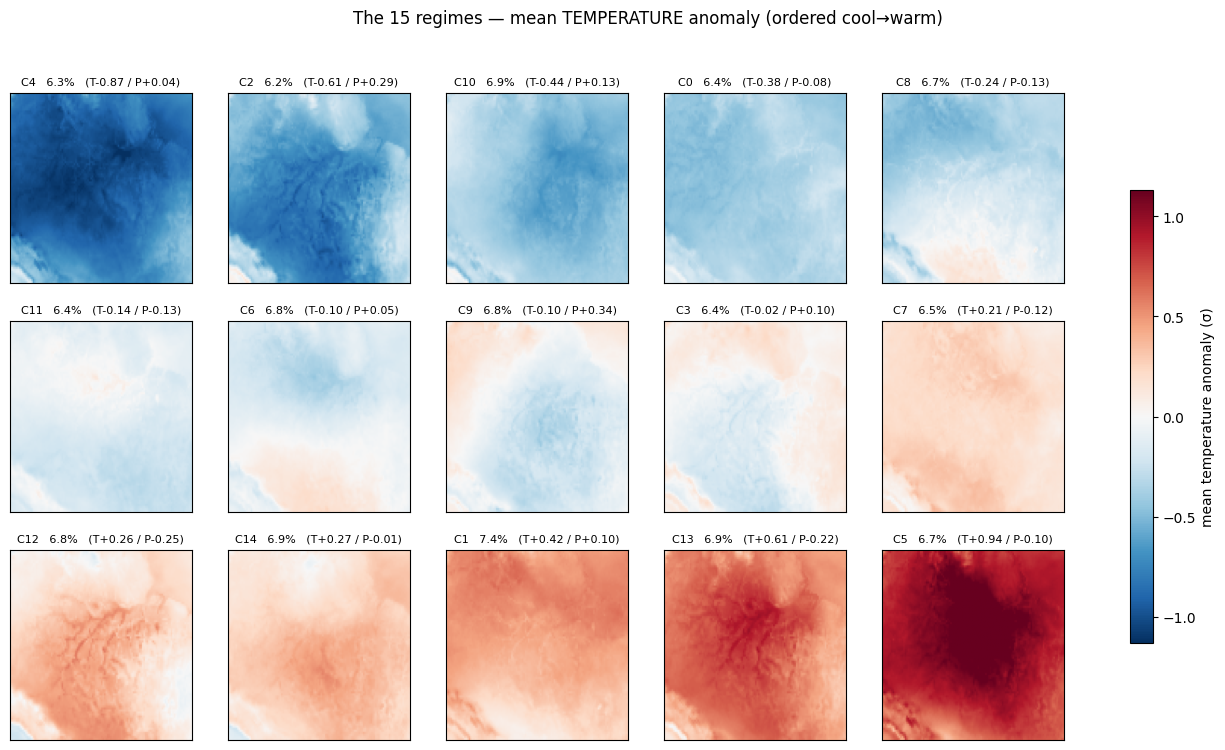

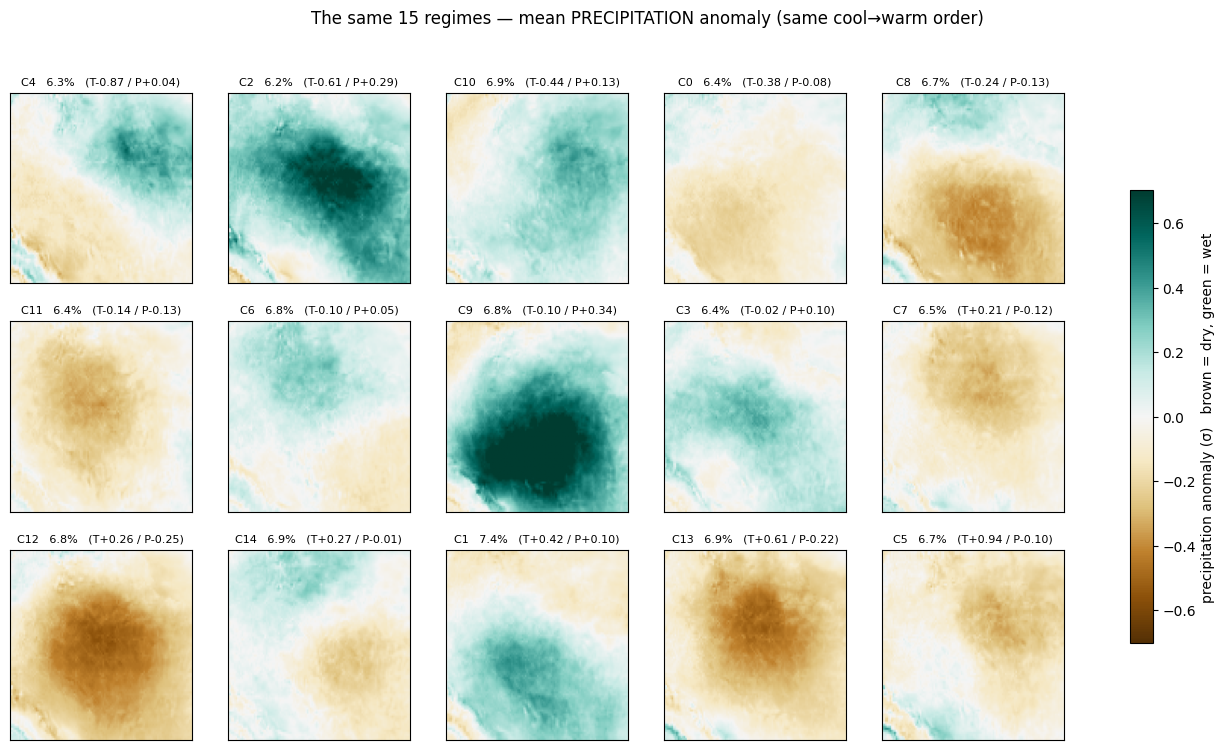

In [4]:
# Temperature and rainfall shown as separate grids: one mean map per regime.
def regime_grid(idxs, ordering, cmap, title, cbar_label):
    comps = np.stack([np.asarray(composite(cid_tr == k))[idxs].mean(0) for k in range(N)])
    vabs  = np.percentile(np.abs(comps), 99)
    ncol = 5; nrow = int(np.ceil(N/ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.4*ncol, 2.8*nrow))
    for ax, k in zip(axes.flat, ordering):
        im = ax.imshow(comps[k], cmap=cmap, vmin=-vabs, vmax=vabs, extent=EXTENT,
                       origin='upper', aspect='auto')
        ax.set_title(f"C{k}   {freq_pct[k]:.1f}%   (T{dommean_T[k]:+.2f} / P{dommean_P[k]:+.2f})",
                     fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
    for ax in axes.flat[N:]: ax.axis('off')
    fig.colorbar(im, ax=axes, shrink=0.7, label=cbar_label)
    fig.suptitle(title, fontsize=12)
    plt.show()
    return comps

comps_T = regime_grid(temp_idx, order, 'RdBu_r',
                      'The 15 regimes — mean TEMPERATURE anomaly (ordered cool→warm)',
                      'mean temperature anomaly (σ)')
if HAS_PREC:
    comps_P = regime_grid(prec_idx, order, 'BrBG',
                          'The same 15 regimes — mean PRECIPITATION anomaly (same cool→warm order)',
                          'precipitation anomaly (σ)   brown = dry, green = wet')

## I.2  The thermo-hydro plane — *new with precipitation*

Each regime placed by its domain-mean temperature anomaly (x) and rainfall
anomaly (y). A temperature-only model can only spread regimes along x; if the
rainfall channel is doing real work, the regimes should spread in y as well.

The physically interesting quadrants are **warm–dry** (bottom-right, the
canonical El Niño Amazonia signature) and **cool–wet** (top-left, La Niña-like).
A strong negative tilt across the cloud means the two fields are coupled, which
is exactly the drought-type behaviour rainfall was added to capture.

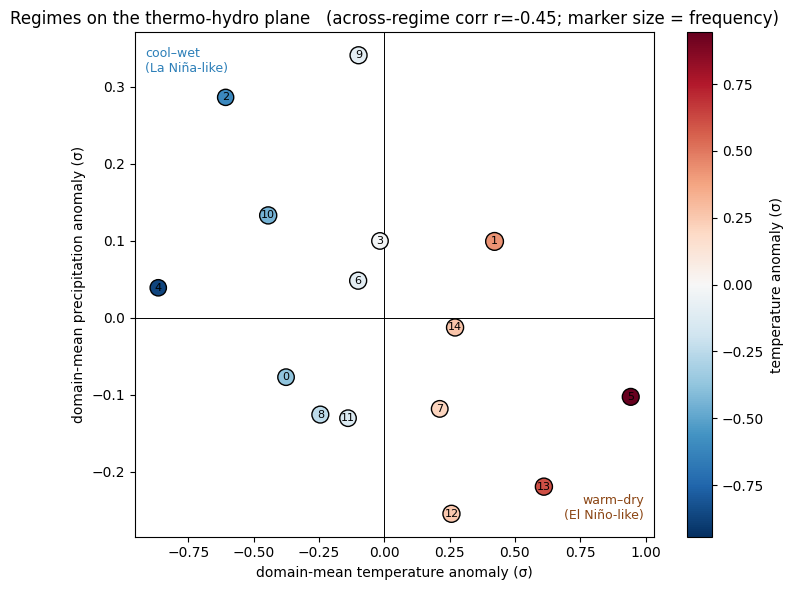

across-regime temperature/precipitation correlation: r = -0.45
precipitation spread across regimes: -0.25 .. +0.34 σ (temperature: -0.87 .. +0.94 σ)
warm-dry regimes: [5, 7, 12, 13, 14]
cool-wet regimes: [2, 3, 4, 6, 9, 10]


In [5]:
if HAS_PREC:
    fig, ax = plt.subplots(figsize=(7.5, 6))
    ax.axhline(0, color='k', lw=.7); ax.axvline(0, color='k', lw=.7)
    sc = ax.scatter(dommean_T, dommean_P, s=freq_pct*22, c=dommean_T,
                    cmap='RdBu_r', edgecolor='k', zorder=3,
                    vmin=-np.abs(dommean_T).max(), vmax=np.abs(dommean_T).max())
    for k in range(N):
        ax.annotate(str(k), (dommean_T[k], dommean_P[k]), fontsize=8,
                    ha='center', va='center', zorder=4)
    r_TP = np.corrcoef(dommean_T, dommean_P)[0, 1]
    xl, yl = ax.get_xlim(), ax.get_ylim()
    ax.text(.98, .03, 'warm–dry\n(El Niño-like)', transform=ax.transAxes,
            ha='right', va='bottom', fontsize=9, color='#8B4513')
    ax.text(.02, .97, 'cool–wet\n(La Niña-like)', transform=ax.transAxes,
            ha='left', va='top', fontsize=9, color='#2c7fb8')
    ax.set_xlabel('domain-mean temperature anomaly (σ)')
    ax.set_ylabel('domain-mean precipitation anomaly (σ)')
    ax.set_title(f'Regimes on the thermo-hydro plane   (across-regime corr r={r_TP:+.2f};'
                 f' marker size = frequency)')
    fig.colorbar(sc, ax=ax, label='temperature anomaly (σ)')
    plt.tight_layout(); plt.show()

    print(f"across-regime temperature/precipitation correlation: r = {r_TP:+.2f}")
    print(f"precipitation spread across regimes: {dommean_P.min():+.2f} .. {dommean_P.max():+.2f} σ "
          f"(temperature: {dommean_T.min():+.2f} .. {dommean_T.max():+.2f} σ)")
    warm_dry = [k for k in range(N) if dommean_T[k] > 0 and dommean_P[k] < 0]
    cool_wet = [k for k in range(N) if dommean_T[k] < 0 and dommean_P[k] > 0]
    print(f"warm-dry regimes: {warm_dry}\ncool-wet regimes: {cool_wet}")

## I.3  Regime summary table

In [6]:
season_of = {12:'DJF',1:'DJF',2:'DJF',3:'MAM',4:'MAM',5:'MAM',
             6:'JJA',7:'JJA',8:'JJA',9:'SON',10:'SON',11:'SON'}
dd = df_day.copy(); dd['season'] = dd['date'].dt.month.map(season_of)
dom_season = pd.crosstab(dd['cluster_id'], dd['season'], normalize='index').idxmax(1)

# mean regime duration (consecutive-day runs)
seq = df_day['cluster_id'].values
gap = (df_day['date'].diff().dt.days.values == 1)
runs = {k: [] for k in range(N)}; cur = seq[0]; L = 1
for i in range(1, len(seq)):
    if seq[i] == cur and gap[i]: L += 1
    else: runs[cur].append(L); cur = seq[i]; L = 1
runs[cur].append(L)
dur = {k: float(np.mean(runs[k])) for k in range(N)}

# long-term frequency trend (%/decade)
yf = monthly.groupby('year')[[f'f{k}' for k in range(N)]].mean()*100
yrs = yf.index.values.astype(float)
trend = {k: float(np.polyfit(yrs, yf[f'f{k}'].values, 1)[0]*10) for k in range(N)}

tbl = pd.DataFrame({
    'freq_%':       freq_pct.round(1),
    'temp_anom':    dommean_T.round(2),
    'prec_anom':    dommean_P.round(2),
    'type':         [('warm' if dommean_T[k] > 0 else 'cool') +
                     ('-dry' if dommean_P[k] < 0 else '-wet') for k in range(N)],
    'dom_season':   [dom_season[k] for k in range(N)],
    'mean_dur_d':   [round(dur[k], 1) for k in range(N)],
    'trend_%/dec':  [round(trend[k], 2) for k in range(N)],
}).rename_axis('cluster')
print(tbl.sort_values('temp_anom').to_string())

         freq_%  temp_anom  prec_anom      type dom_season  mean_dur_d  trend_%/dec
cluster                                                                            
4           6.3      -0.87       0.04  cool-wet        DJF         3.0        -3.73
2           6.2      -0.61       0.29  cool-wet        SON         2.0        -3.36
10          6.9      -0.44       0.13  cool-wet        DJF         2.0        -1.85
0           6.4      -0.38      -0.08  cool-dry        JJA         1.7        -2.94
8           6.7      -0.24      -0.13  cool-dry        DJF         1.9        -1.13
11          6.4      -0.14      -0.13  cool-dry        SON         1.5        -0.76
9           6.8      -0.10       0.34  cool-wet        MAM         1.6         0.73
6           6.8      -0.10       0.05  cool-wet        DJF         1.6        -0.68
3           6.4      -0.02       0.10  cool-wet        JJA         1.6        -1.12
7           6.5       0.21      -0.12  warm-dry        SON         1.6      

## I.4  Seasonality — when each regime occurs

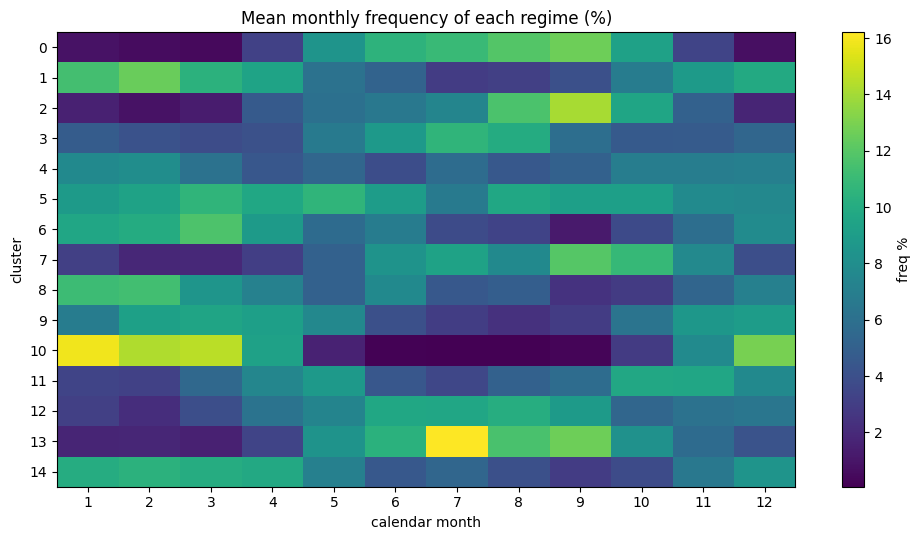

mean seasonal span (max-min monthly freq) = 9.2%  -> weak residual seasonality (deseasonalised: regimes are ~season-independent)


In [7]:
mfreq = (monthly.groupby('month')[[f'f{k}' for k in range(N)]].mean()*100)
mfreq.columns = range(N)
fig, ax = plt.subplots(figsize=(10, 5.5))
im = ax.imshow(mfreq.T, aspect='auto', cmap='viridis')
ax.set_yticks(range(N)); ax.set_ylabel('cluster')
ax.set_xticks(range(12)); ax.set_xticklabels(range(1, 13)); ax.set_xlabel('calendar month')
ax.set_title('Mean monthly frequency of each regime (%)')
fig.colorbar(im, label='freq %'); plt.tight_layout(); plt.show()
span = (mfreq.max() - mfreq.min()).mean()
print(f"mean seasonal span (max-min monthly freq) = {span:.1f}%  "
      f"-> {'strong' if span>10 else 'weak'} residual seasonality "
      f"({'seasonal model' if span>10 else 'deseasonalised: regimes are ~season-independent'})")

## I.5  Persistence & transitions — regimes as coherent states

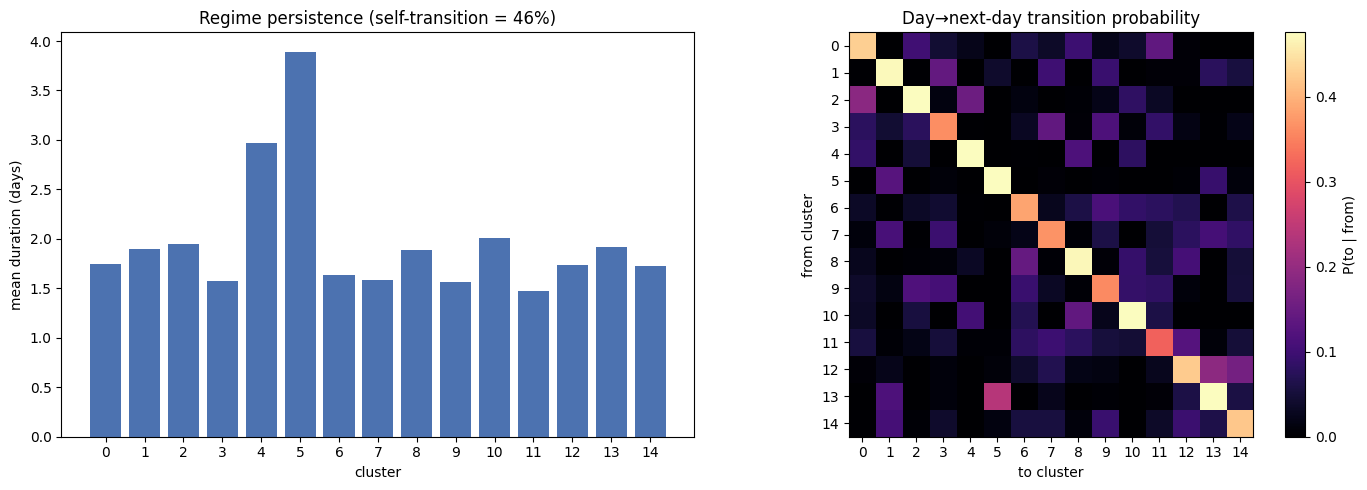

In [8]:
Tm = np.zeros((N, N))
for i in range(1, len(seq)):
    if gap[i]: Tm[seq[i-1], seq[i]] += 1
Tn = Tm / np.maximum(Tm.sum(1, keepdims=True), 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(range(N), [dur[k] for k in range(N)], color='#4c72b0')
axes[0].set_xlabel('cluster'); axes[0].set_ylabel('mean duration (days)')
axes[0].set_title(f'Regime persistence (self-transition = {np.diag(Tn).mean():.0%})')
axes[0].set_xticks(range(N))
im = axes[1].imshow(Tn, cmap='magma', vmin=0, vmax=np.percentile(Tn, 98))
axes[1].set_title('Day→next-day transition probability')
axes[1].set_xlabel('to cluster'); axes[1].set_ylabel('from cluster')
axes[1].set_xticks(range(N)); axes[1].set_yticks(range(N))
fig.colorbar(im, ax=axes[1], label='P(to | from)'); plt.tight_layout(); plt.show()

## I.6  Long-term change — regime frequency through the decades

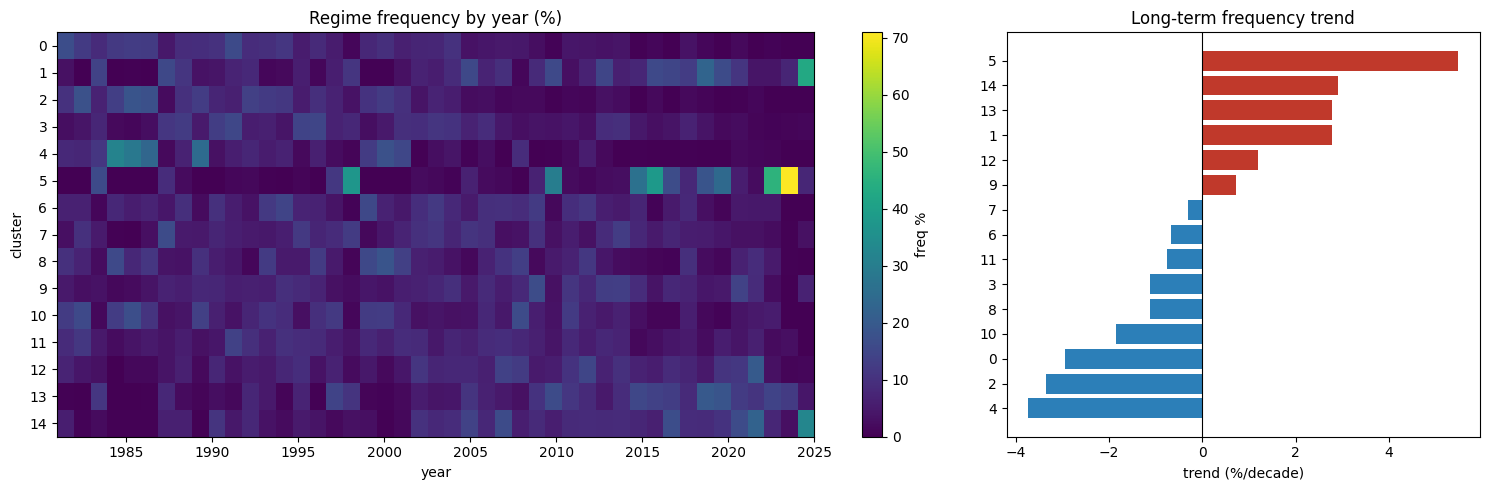

regimes getting MORE frequent (top) vs LESS (bottom):
  rising : {5: 5.49, 14: 2.91, 13: 2.78}
  falling: {4: -3.73, 2: -3.36, 0: -2.94}
  (types: {5: 'warm-dry', 14: 'warm-dry', 13: 'warm-dry'} rising | {4: 'cool-wet', 2: 'cool-wet', 0: 'cool-dry'} falling)


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios':[2,1]})
im = axes[0].imshow(yf.T, aspect='auto', cmap='viridis',
                    extent=[yrs.min(), yrs.max(), N-.5, -.5])
axes[0].set_yticks(range(N)); axes[0].set_ylabel('cluster'); axes[0].set_xlabel('year')
axes[0].set_title('Regime frequency by year (%)')
fig.colorbar(im, ax=axes[0], label='freq %')
ts = sorted(range(N), key=lambda k: trend[k])
axes[1].barh(range(N), [trend[k] for k in ts],
             color=['#2c7fb8' if trend[k] < 0 else '#c0392b' for k in ts])
axes[1].set_yticks(range(N)); axes[1].set_yticklabels(ts)
axes[1].axvline(0, color='k', lw=.8); axes[1].set_xlabel('trend (%/decade)')
axes[1].set_title('Long-term frequency trend')
plt.tight_layout(); plt.show()
print("regimes getting MORE frequent (top) vs LESS (bottom):")
print("  rising :", {k: round(trend[k],2) for k in ts[::-1][:3]})
print("  falling:", {k: round(trend[k],2) for k in ts[:3]})
print("  (types:", {k: tbl['type'][k] for k in ts[::-1][:3]}, "rising |",
      {k: tbl['type'][k] for k in ts[:3]}, "falling)")

## I.7  Physical sanity check — do the regimes hold in *every* month?

The composites above are in standardised anomaly units. Here we reconstruct the
**raw fields** (temperature in K, rainfall in mm/day — not deseasonalised) and
show each regime's mean domain departure from **each calendar month's**
climatology. This is the seasonally-fair test: a genuinely "warm" or "dry" regime
should be warmer/drier than normal in *every* month it occurs — not merely because
it happens in a hot or rainy season.

With rainfall in the mix we check four regimes: the warmest, the coolest, the
**wettest** and the **driest**.

In [10]:
from src.data_manager import Era5Dataset
# raw (non-deseasonalised) fields, same split & ordering as cid_tr.
# Hits the same daily cache as the training run, so this is fast.
raw_ds = Era5Dataset(transform=None, surf_vars=vars_names, lat_lim=lat_lim, lon_lim=lon_lim,
                     split_val=True, val_years=params['data']['val_years'],
                     deseason_standardize=False)
raw_imgs = raw_ds.imgs                                     # (T,V,H,W) K and mm/day
assert raw_imgs.shape[0] == len(cid_tr), "raw fields must align with cluster assignments"

month_tr = tr['date'].dt.month.values
dm_raw   = raw_imgs.mean((2, 3)).numpy()                   # (T,V) domain-mean raw field
clim_m   = np.stack([dm_raw[month_tr == m].mean(0) for m in range(1, 13)])  # (12,V)

def month_departure(k):
    d = np.full((12, V), np.nan)
    for m in range(1, 13):
        s = (month_tr == m) & (cid_tr == k)
        if s.sum():
            d[m-1] = dm_raw[s].mean(0) - clim_m[m-1]
    return d

sanity = list(dict.fromkeys([order[-1], order[0]] +
                            ([order_P[-1], order_P[0]] if HAS_PREC else [order[-2], order[1]])))
labels = {order[-1]: 'warmest', order[0]: 'coolest'}
if HAS_PREC:
    labels.setdefault(order_P[-1], 'wettest'); labels.setdefault(order_P[0], 'driest')
print("checking regimes:", {k: labels.get(k, '') for k in sanity})

INFO:root:loaded cached daily tensor from ../data/era5/.daily_cache/daily_59b624db52101a4a.pt


checking regimes: {np.int64(5): 'warmest', np.int64(4): 'coolest', np.int64(9): 'wettest', np.int64(12): 'driest'}


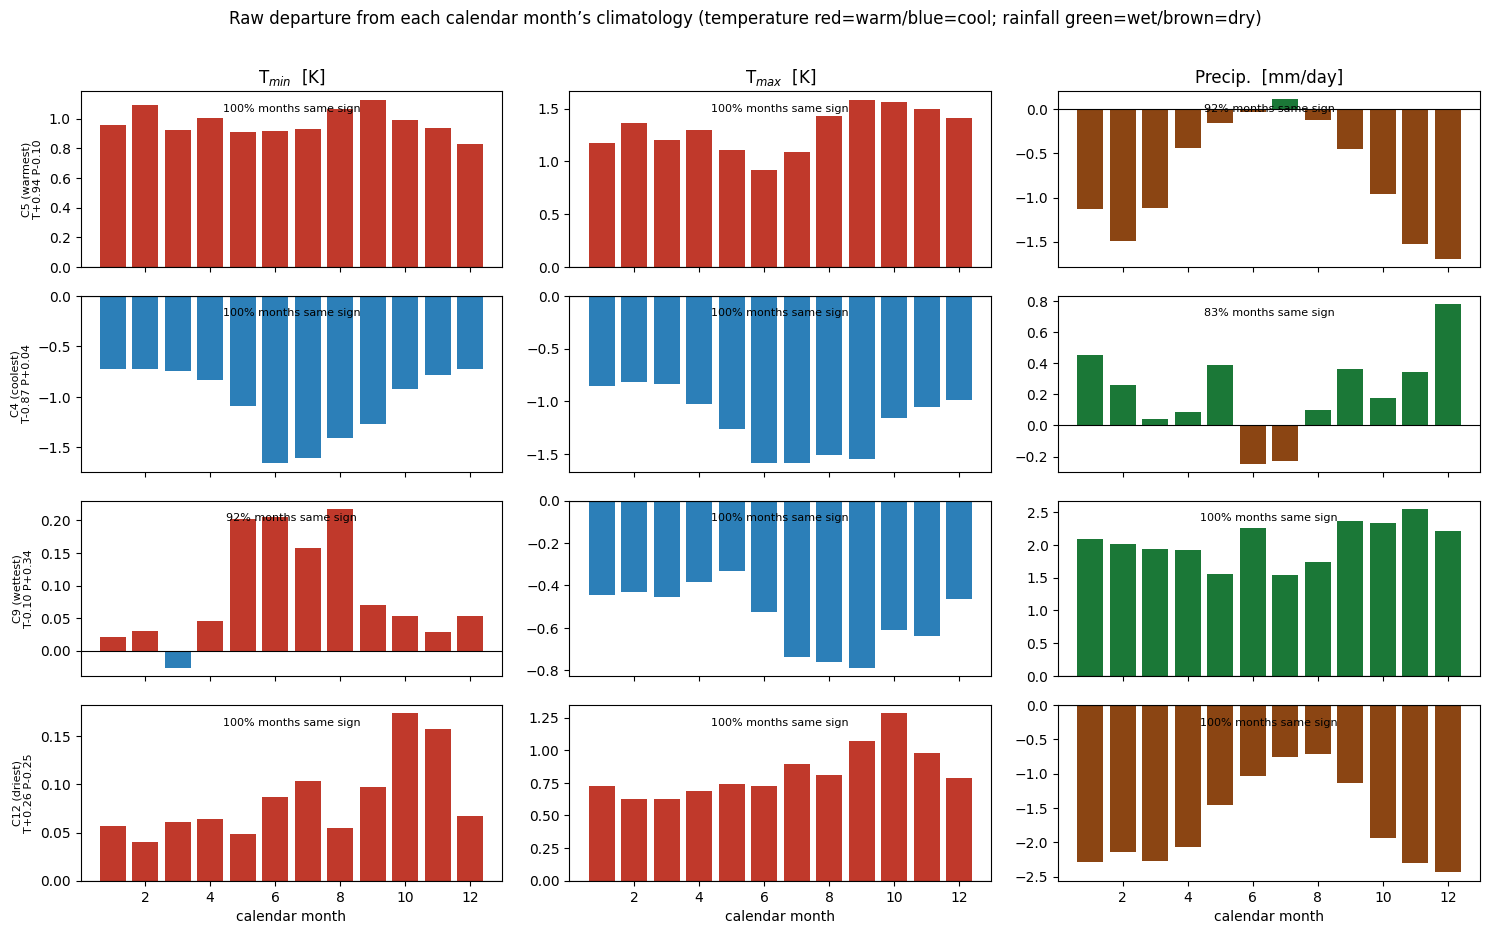

Consistency (fraction of months the departure keeps the regime's overall sign):
  C5 [warmest]: T$_{min}$ 100% (mean +0.97 K) | T$_{max}$ 100% (mean +1.30 K) | Precip. 92% (mean -0.75 mm/day)
  C4 [coolest]: T$_{min}$ 100% (mean -1.04 K) | T$_{max}$ 100% (mean -1.18 K) | Precip. 83% (mean +0.21 mm/day)
  C9 [wettest]: T$_{min}$ 92% (mean +0.09 K) | T$_{max}$ 100% (mean -0.55 K) | Precip. 100% (mean +2.04 mm/day)
  C12 [driest]: T$_{min}$ 100% (mean +0.08 K) | T$_{max}$ 100% (mean +0.83 K) | Precip. 100% (mean -1.71 mm/day)


In [11]:
fig, axes = plt.subplots(len(sanity), V, figsize=(5*V, 2.3*len(sanity)),
                         sharex=True, squeeze=False)
for i, k in enumerate(sanity):
    d = month_departure(k)
    for v in range(V):
        ax = axes[i][v]
        pos, neg = ('#c0392b', '#2c7fb8') if meta[v]['kind'] == 'temp' else ('#1b7837', '#8B4513')
        ax.bar(range(1, 13), d[:, v], color=[pos if x > 0 else neg for x in d[:, v]])
        ax.axhline(0, color='k', lw=.8)
        cons = np.nanmean(np.sign(d[:, v]) == np.sign(np.nanmean(d[:, v]))) * 100
        ax.text(.5, .93, f"{cons:.0f}% months same sign", transform=ax.transAxes,
                ha='center', va='top', fontsize=8)
        if i == 0: ax.set_title(f"{meta[v]['label']}  [{meta[v]['unit']}]")
        if v == 0: ax.set_ylabel(f"C{k} ({labels.get(k,'')})\nT{dommean_T[k]:+.2f} P{dommean_P[k]:+.2f}",
                                 fontsize=8)
for v in range(V): axes[-1][v].set_xlabel('calendar month')
fig.suptitle('Raw departure from each calendar month’s climatology '
             '(temperature red=warm/blue=cool; rainfall green=wet/brown=dry)', y=1.01)
plt.tight_layout(); plt.show()

print("Consistency (fraction of months the departure keeps the regime's overall sign):")
for k in sanity:
    d = month_departure(k)
    parts = [f"{meta[v]['label']} {np.nanmean(np.sign(d[:,v])==np.sign(np.nanmean(d[:,v])))*100:.0f}%"
             f" (mean {np.nanmean(d[:,v]):+.2f} {meta[v]['unit']})" for v in range(V)]
    print(f"  C{k} [{labels.get(k,'')}]: " + " | ".join(parts))

## I.8  Does the model actually *use* precipitation? — *new*

Adding a channel does not guarantee the encoder uses it. Two checks:

1. **η² per channel** — the share of each field's total variance explained by the
   cluster partition. If the rainfall η² were ~0, the regimes would be
   temperature states with rainfall along for the ride, and every
   precipitation-based conclusion below would be decoration.
2. **z-score health** — rainfall is strongly non-Gaussian (many near-zero days,
   rare extremes), yet it receives the same per-month per-cell standardisation as
   temperature. A heavily skewed, long-tailed rainfall channel is the signature
   that a log/cube-root transform before standardising would help.

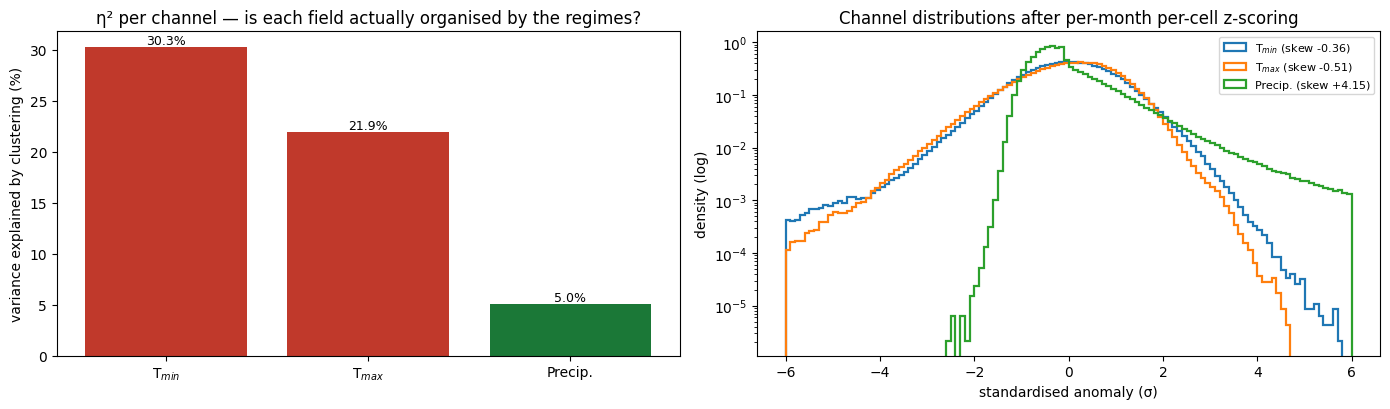

 T$_{min}$: eta2= 30.3%  skew=-0.36  excess-kurt=+1.60
 T$_{max}$: eta2= 21.9%  skew=-0.51  excess-kurt=+0.78
   Precip.: eta2=  5.0%  skew=+4.15  excess-kurt=+39.94

precipitation eta2 is 0.19x the mean temperature eta2 -> rainfall is a SECONDARY driver; regimes are mostly thermal
NOTE: strong rainfall skew — a log/cube-root transform before standardising is worth testing (see summary).


In [12]:
# --- 1. eta^2: variance explained by the cluster partition, per channel ------ #
eta2 = np.zeros(V)
for v in range(V):
    x  = imgs[:, v]                              # (T,H,W)
    gm = x.mean(0)
    ss_tot = ((x - gm) ** 2).sum().item()
    ss_bet = 0.0
    for k in range(N):
        m = (cid_tr == k)
        if m.sum() == 0: continue
        ss_bet += m.sum() * ((x[m].mean(0) - gm) ** 2).sum().item()
    eta2[v] = ss_bet / ss_tot

# --- 2. distribution of the standardised channels ---------------------------- #
from scipy.stats import skew, kurtosis
samp = imgs[::37].reshape(-1, V, H*W).permute(1, 0, 2).reshape(V, -1).numpy()  # subsample days

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].bar(range(V), eta2*100, color=['#c0392b' if m['kind']=='temp' else '#1b7837' for m in meta])
axes[0].set_xticks(range(V)); axes[0].set_xticklabels([m['label'] for m in meta])
axes[0].set_ylabel('variance explained by clustering (%)')
axes[0].set_title('η² per channel — is each field actually organised by the regimes?')
for v in range(V):
    axes[0].text(v, eta2[v]*100, f'{eta2[v]*100:.1f}%', ha='center', va='bottom', fontsize=9)

for v in range(V):
    axes[1].hist(samp[v], bins=120, range=(-6, 6), histtype='step', lw=1.6,
                 density=True, label=f"{meta[v]['label']} (skew {skew(samp[v]):+.2f})")
axes[1].set_yscale('log'); axes[1].set_xlabel('standardised anomaly (σ)')
axes[1].set_ylabel('density (log)'); axes[1].legend(fontsize=8)
axes[1].set_title('Channel distributions after per-month per-cell z-scoring')
plt.tight_layout(); plt.show()

for v in range(V):
    print(f"{meta[v]['label']:>10}: eta2={eta2[v]*100:5.1f}%  skew={skew(samp[v]):+.2f}  "
          f"excess-kurt={kurtosis(samp[v]):+.2f}")
if HAS_PREC:
    pv = prec_idx[0]
    ratio = eta2[pv] / max(eta2[temp_idx].mean(), 1e-9)
    print(f"\nprecipitation eta2 is {ratio:.2f}x the mean temperature eta2 -> "
          + ('rainfall is a co-equal driver of the partition' if ratio > 0.5 else
             'rainfall is a SECONDARY driver; regimes are mostly thermal'))
    if abs(skew(samp[pv])) > 1.5:
        print("NOTE: strong rainfall skew — a log/cube-root transform before "
              "standardising is worth testing (see summary).")

---
# Part II — ENSO as one application

Having characterized the regimes, we now test how ENSO modulates their frequency,
using the significance-aware machinery below. Statistically this part is identical
to the temperature-only notebook — the difference is that the regimes being counted
now carry rainfall information, so the effects (if any) should be easier to detect.

## 1. Omnibus gate — is there *any* ENSO signal?

One global test before looking at individual clusters. If this fails, per-cluster
"findings" are just multiple-comparison noise and should not be interpreted.

In [13]:
stat, p = es.omnibus_test(monthly, N, n_perm=N_PERM)
verdict = "SIGNAL: ONI is related to cluster occupancy" if p < 0.05 else \
          "NO GLOBAL SIGNAL: do not interpret individual clusters"
print(f"omnibus  sum(corr^2) = {stat:.3f}   p = {p:.4f}\n=> {verdict}")

omnibus  sum(corr^2) = 0.421   p = 0.0130
=> SIGNAL: ONI is related to cluster occupancy


## 2. Continuous-ONI response per cluster

Correlation between each cluster's monthly frequency and ONI (uses the full
signed gradient). Bars colored by significance:
**red = survives family-wise (FWER) correction**, orange = raw p<0.05 only,
grey = not significant. Whiskers = 95% year-block bootstrap CI.

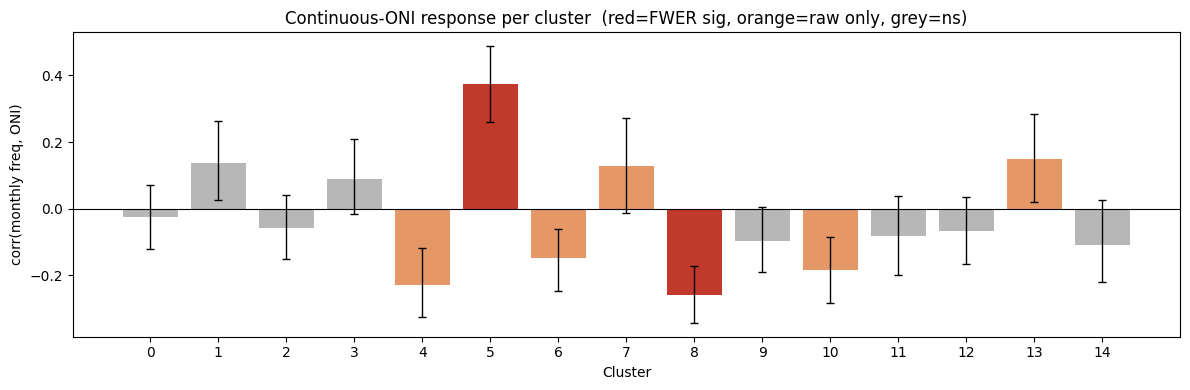

          corr  p_raw  p_fwer  ci_lo  ci_hi      type
cluster                                              
0       -0.025  0.654   1.000 -0.121  0.071  cool-dry
1        0.138  0.110   0.398  0.026  0.263  warm-wet
2       -0.057  0.399   0.987 -0.152  0.040  cool-wet
3        0.090  0.175   0.845 -0.016  0.209  cool-wet
4       -0.230  0.013   0.052 -0.326 -0.119  cool-wet
5        0.376  0.011   0.011  0.259  0.488  warm-dry
6       -0.149  0.015   0.321 -0.247 -0.063  cool-wet
7        0.129  0.021   0.466 -0.012  0.272  warm-dry
8       -0.260  0.015   0.021 -0.344 -0.172  cool-dry
9       -0.096  0.087   0.790 -0.190  0.005  cool-wet
10      -0.185  0.022   0.138 -0.285 -0.087  cool-wet
11      -0.082  0.126   0.895 -0.198  0.038  cool-dry
12      -0.069  0.145   0.960 -0.167  0.036  warm-dry
13       0.148  0.031   0.331  0.019  0.284  warm-dry
14      -0.108  0.079   0.679 -0.222  0.026  warm-dry

raw p<0.05: 7/15  (expected ~0.8 by chance) | FWER<0.05: 2/15


In [14]:
resp = es.oni_response(monthly, N, n_perm=N_PERM)
lo, hi = es.bootstrap_ci_oni_corr(monthly, N, n_boot=N_BOOT)
resp['ci_lo'], resp['ci_hi'] = lo, hi

def sig_colors(p_fwer, p_raw):
    out = []
    for k in range(len(p_fwer)):
        if p_fwer[k] < 0.05:   out.append('#c0392b')
        elif p_raw[k] < 0.05:  out.append('#e59866')
        else:                  out.append('#b7b7b7')
    return out

fig, ax = plt.subplots(figsize=(12, 4))
c = sig_colors(resp.p_fwer.values, resp.p_raw.values)
ax.bar(resp.index, resp['corr'], color=c)
ax.errorbar(resp.index, resp['corr'],
            yerr=[resp['corr']-resp.ci_lo, resp.ci_hi-resp['corr']],
            fmt='none', ecolor='black', capsize=3, lw=1)
ax.axhline(0, color='k', lw=.8)
ax.set_xlabel('Cluster'); ax.set_ylabel('corr(monthly freq, ONI)')
ax.set_title('Continuous-ONI response per cluster  (red=FWER sig, orange=raw only, grey=ns)')
ax.set_xticks(range(N)); plt.tight_layout(); plt.show()

resp_show = resp.copy(); resp_show['type'] = [tbl['type'][k] for k in resp.index]
print(resp_show.round(3).to_string())
print(f"\nraw p<0.05: {(resp.p_raw<0.05).sum()}/{N}  "
      f"(expected ~{0.05*N:.1f} by chance) | FWER<0.05: {(resp.p_fwer<0.05).sum()}/{N}")

## 3. El Niño occurrence anomaly — the original plot, done honestly

Same quantity as `analysis.ipynb` section 4 ( P(k|El Niño) − P(k) ), but now with
95% bootstrap CIs and an autocorrelation-aware null. **A bar whose CI crosses 0
is not a reliable effect**, however tall it looks.

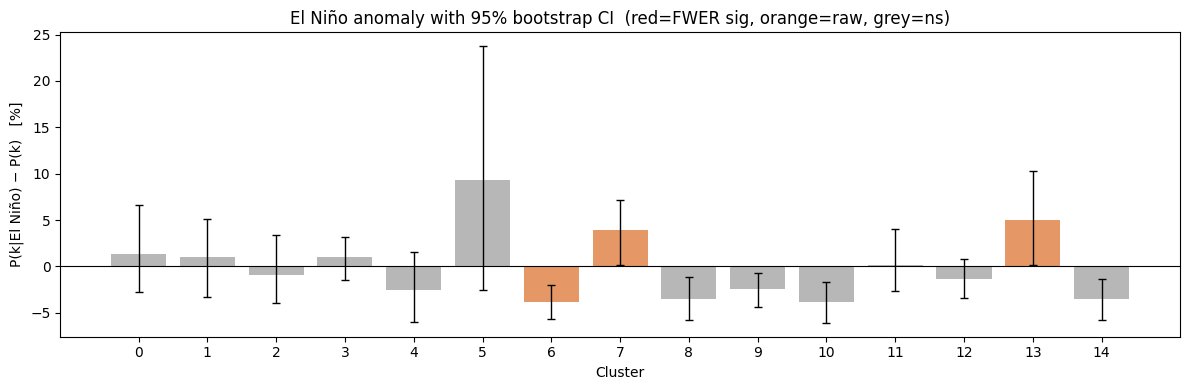

         anom  ci_lo  ci_hi  p_raw  p_fwer
cluster                                   
5        9.36  -2.49  23.75   0.09    0.09
13       5.03   0.17  10.28   0.03    0.45
7        3.98   0.16   7.16   0.01    0.66
10      -3.87  -6.08  -1.68   0.10    0.69
6       -3.78  -5.68  -1.97   0.01    0.72
14      -3.54  -5.75  -1.34   0.07    0.77
8       -3.53  -5.78  -1.12   0.06    0.77
4       -2.54  -5.93   1.59   0.44    0.95
9       -2.45  -4.41  -0.70   0.11    0.96
12      -1.39  -3.44   0.79   0.40    1.00
0        1.38  -2.74   6.65   0.52    1.00
1        1.02  -3.30   5.16   0.61    1.00
3        1.00  -1.43   3.22   0.52    1.00
2       -0.87  -3.97   3.44   0.73    1.00
11       0.20  -2.66   4.01   0.81    1.00


In [15]:
an = es.elnino_anomaly(monthly, N, n_perm=N_PERM, n_boot=N_BOOT)
fig, ax = plt.subplots(figsize=(12, 4))
c = sig_colors(an.p_fwer.values, an.p_raw.values)
ax.bar(an.index, an['anom'], color=c)
ax.errorbar(an.index, an['anom'], yerr=[an['anom']-an.ci_lo, an.ci_hi-an['anom']],
            fmt='none', ecolor='black', capsize=3, lw=1)
ax.axhline(0, color='k', lw=.8)
ax.set_xlabel('Cluster'); ax.set_ylabel('P(k|El Niño) − P(k)   [%]')
ax.set_title('El Niño anomaly with 95% bootstrap CI  (red=FWER sig, orange=raw, grey=ns)')
ax.set_xticks(range(N)); plt.tight_layout(); plt.show()
print(an.reindex(an.anom.abs().sort_values(ascending=False).index).round(2).to_string())

## 4. Lagged response — cross-correlation instead of per-cell heatmaps

For each cluster, corr(monthly freq(t), ONI(t−lag)) across lags. Cells that
survive the **family-wise** max-statistic correction (over all clusters × lags)
are outlined in black — everything else is within noise.

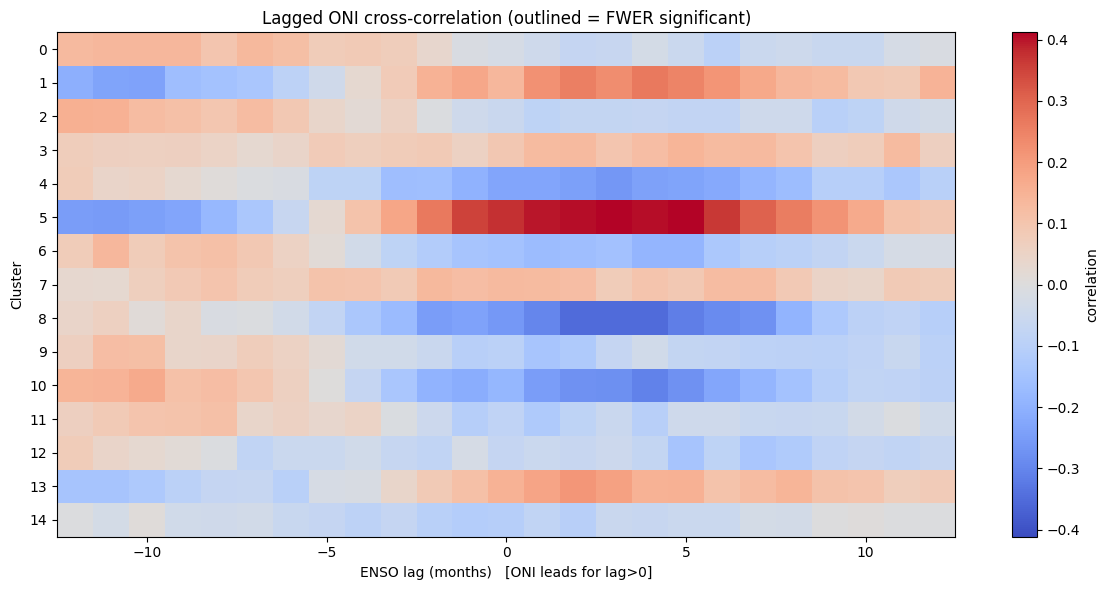

0 of 375 (cluster,lag) cells survive family-wise correction


In [16]:
lags, cc, pf = es.lag_crosscorr(monthly, N, max_lag=12, n_perm=N_PERM)
fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(cc, aspect='auto', cmap='coolwarm', vmin=-np.abs(cc).max(), vmax=np.abs(cc).max(),
               extent=[lags[0]-.5, lags[-1]+.5, N-.5, -.5])
for k in range(N):
    for j, L in enumerate(lags):
        if pf[k, j] < 0.05:
            ax.add_patch(plt.Rectangle((L-.5, k-.5), 1, 1, fill=False, edgecolor='k', lw=2))
ax.set_xlabel('ENSO lag (months)   [ONI leads for lag>0]'); ax.set_ylabel('Cluster')
ax.set_yticks(range(N)); ax.set_title('Lagged ONI cross-correlation (outlined = FWER significant)')
fig.colorbar(im, ax=ax, label='correlation'); plt.tight_layout(); plt.show()
nsig = int((pf < 0.05).sum())
print(f"{nsig} of {pf.size} (cluster,lag) cells survive family-wise correction")

## 5. Robustness — does the signal reproduce across time?

Per-cluster ONI correlation computed on the first vs second half of the record.
Points near the diagonal = stable (real) effects; scatter = noise. Only trust
clusters that are significant **and** land near the diagonal.

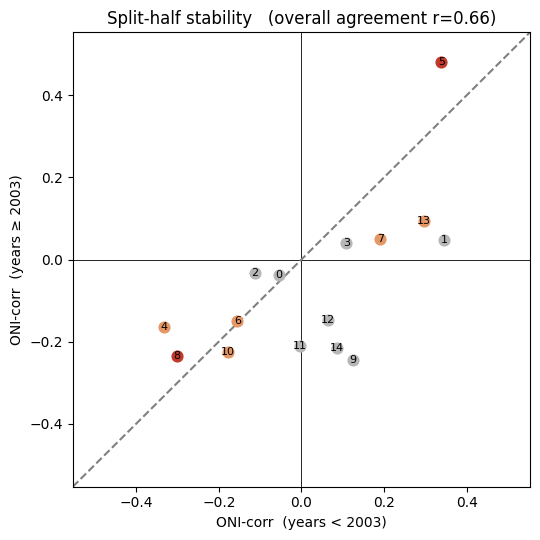

In [17]:
sh, r, mid = es.split_half(monthly, N)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.axhline(0, color='k', lw=.6); ax.axvline(0, color='k', lw=.6)
lim = np.abs(sh.values).max()*1.15
ax.plot([-lim, lim], [-lim, lim], '--', color='grey')
for k in range(N):
    col = '#c0392b' if resp.p_fwer[k] < 0.05 else ('#e59866' if resp.p_raw[k] < 0.05 else '#b7b7b7')
    ax.scatter(sh.corr_firsthalf[k], sh.corr_secondhalf[k], color=col, s=60, zorder=3)
    ax.annotate(str(k), (sh.corr_firsthalf[k], sh.corr_secondhalf[k]), fontsize=8,
                ha='center', va='center')
ax.set_xlabel(f'ONI-corr  (years < {mid})'); ax.set_ylabel(f'ONI-corr  (years ≥ {mid})')
ax.set_title(f'Split-half stability   (overall agreement r={r:.2f})')
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); plt.tight_layout(); plt.show()

## 6. What do the ENSO-linked regimes look like? (physical interpretation)

We composite the **deseasonalised anomaly** fields (native resolution, training
days) for the clusters that passed every statistical gate — now one column per
variable, so each ENSO-linked regime is described by its temperature *and*
rainfall pattern.

In [18]:
# robust = clusters passing FWER in Part II §2 (fallback: strongest |corr|)
robust = [k for k in range(N) if resp.p_fwer[k] < 0.05]
if not robust:
    robust = list(resp['corr'].abs().sort_values(ascending=False).index[:3])
    print('(no cluster survived FWER — falling back to the 3 strongest |corr| for illustration;'
          ' these are NOT significant findings)')
print('ENSO-linked regimes:', robust,
      '| ONI corr:', {k: round(float(resp['corr'][k]), 2) for k in robust},
      '| type:', {k: tbl['type'][k] for k in robust})

ENSO-linked regimes: [5, 8] | ONI corr: {5: 0.38, 8: -0.26} | type: {5: 'warm-dry', 8: 'cool-dry'}


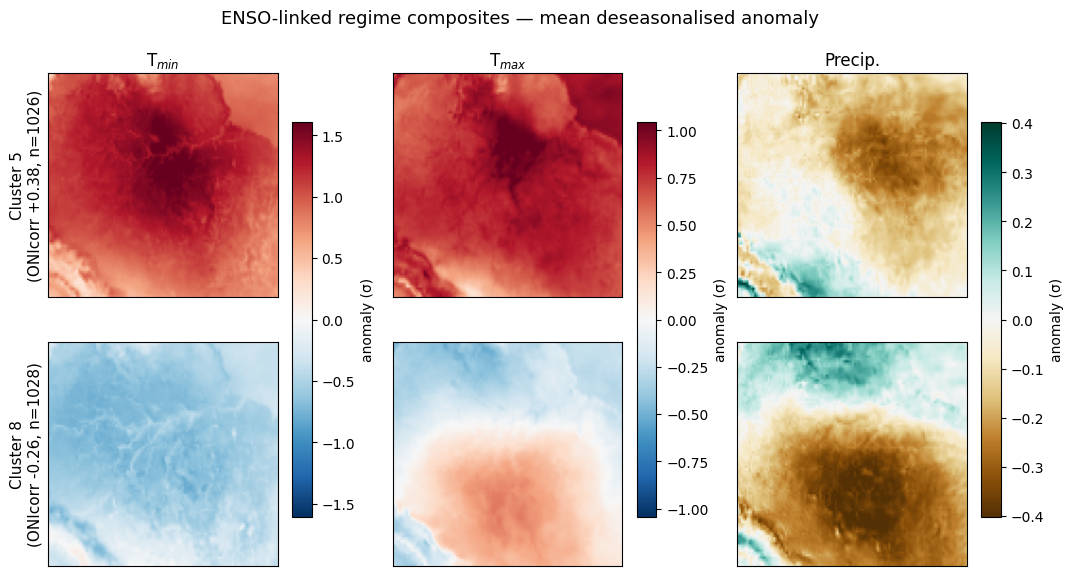

In [19]:
maps = [composite(cid_tr == k) for k in robust]
titles = [f"Cluster {k}\n(ONIcorr {resp['corr'][k]:+.2f}, n={int((cid_tr==k).sum())})" for k in robust]
vabs = show_maps(maps, titles, 'ENSO-linked regime composites — mean deseasonalised anomaly')

## 7. Do the regimes match the ENSO fingerprint? — *extended to rainfall*

First the **direct ENSO signature**: mean anomaly on El Niño vs La Niña months,
now for temperature *and* rainfall. Over Amazonia the textbook El Niño response is
**warm and dry**, so the El Niño row should be red in the temperature columns and
brown in the rainfall column.

Then we measure the **spatial correlation** between each cluster's composite and
the El Niño composite — computed **separately per field**. This is the payoff of
the extra channel: a regime can now be checked for matching ENSO in temperature
*and* in rainfall, and a regime that matches in **both** is far more convincing
than one that matches in temperature alone.

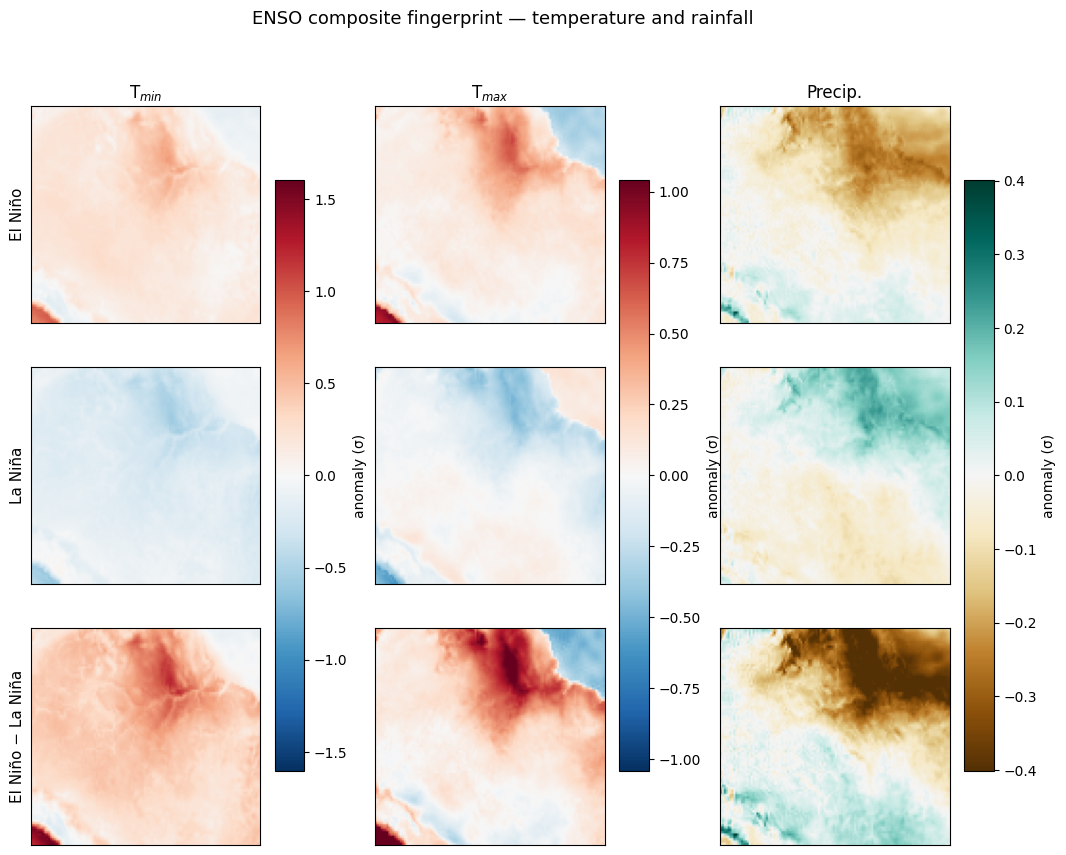

domain-mean ENSO signature (σ):
   El Niño: T$_{min}$ +0.188  T$_{max}$ +0.110  Precip. -0.067
   La Niña: T$_{min}$ -0.197  T$_{max}$ -0.067  Precip. +0.021


In [20]:
el_map = composite(tr.Label.values == 'El Niño')
ln_map = composite(tr.Label.values == 'La Niña')
show_maps([el_map, ln_map, el_map - ln_map],
          ['El Niño', 'La Niña', 'El Niño − La Niña'],
          'ENSO composite fingerprint — temperature and rainfall', vabs=vabs)

print("domain-mean ENSO signature (σ):")
for nm, mp in [('El Niño', el_map), ('La Niña', ln_map)]:
    print(f"  {nm:>8}: " + "  ".join(f"{meta[v]['label']} {mp[v].mean():+.3f}" for v in range(V)))

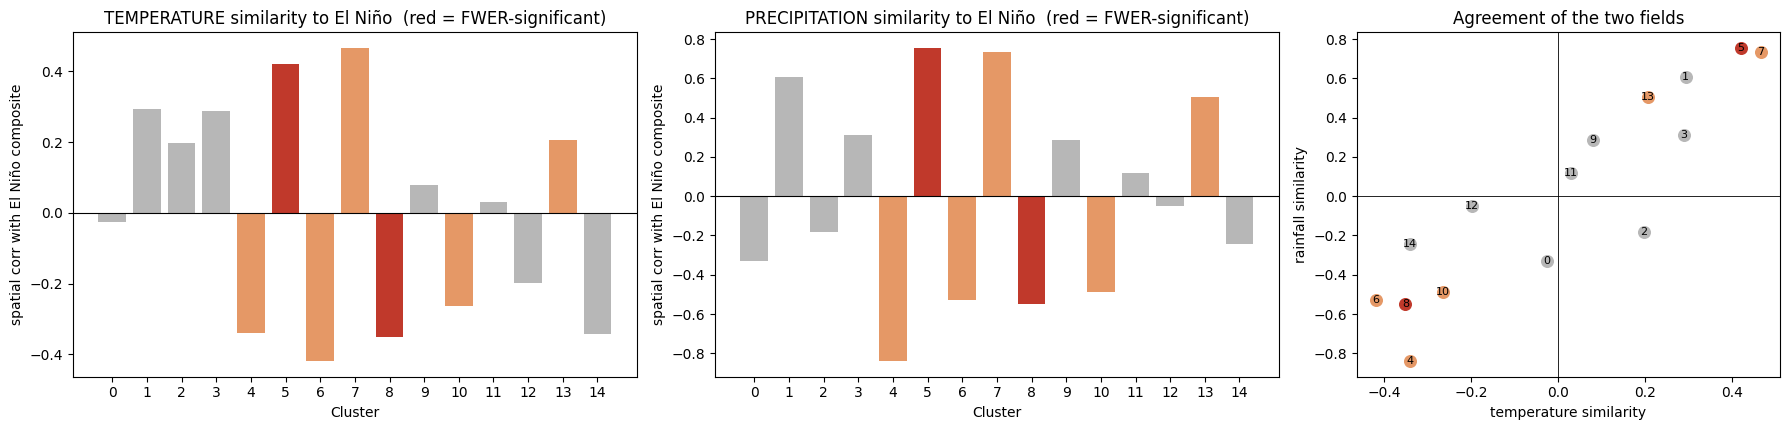

cluster: ONIcorr | simT | simP | verdict
  C5: +0.38 | +0.42 | +0.75 -> El Niño-like in BOTH fields
  C8: -0.26 | -0.35 | -0.55 -> La Niña-like in BOTH fields


In [21]:
def spatial_corr(a, b):
    a = np.asarray(a).ravel(); b = np.asarray(b).ravel()
    a = a - a.mean(); b = b - b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-9))

comps_all = [composite(cid_tr == k) for k in range(N)]
sim_T = np.array([spatial_corr(np.stack([c[v] for v in temp_idx]),
                               np.stack([el_map[v] for v in temp_idx])) for c in comps_all])
sim_P = (np.array([spatial_corr(np.stack([c[v] for v in prec_idx]),
                                np.stack([el_map[v] for v in prec_idx])) for c in comps_all])
         if HAS_PREC else np.zeros(N))
cols = sig_colors(resp.p_fwer.values, resp.p_raw.values)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.4), gridspec_kw={'width_ratios':[2,2,1.5]})
for ax, s, ttl in [(axes[0], sim_T, 'TEMPERATURE'), (axes[1], sim_P, 'PRECIPITATION')]:
    ax.bar(range(N), s, color=cols); ax.axhline(0, color='k', lw=.8)
    ax.set_xlabel('Cluster'); ax.set_ylabel('spatial corr with El Niño composite')
    ax.set_title(f'{ttl} similarity to El Niño  (red = FWER-significant)')
    ax.set_xticks(range(N))
# agreement plane: does a regime look like El Nino in BOTH fields?
axes[2].axhline(0, color='k', lw=.6); axes[2].axvline(0, color='k', lw=.6)
for k in range(N):
    axes[2].scatter(sim_T[k], sim_P[k], color=cols[k], s=70, zorder=3)
    axes[2].annotate(str(k), (sim_T[k], sim_P[k]), fontsize=8, ha='center', va='center', zorder=4)
axes[2].set_xlabel('temperature similarity'); axes[2].set_ylabel('rainfall similarity')
axes[2].set_title('Agreement of the two fields')
plt.tight_layout(); plt.show()

print("cluster: ONIcorr | simT | simP | verdict")
for k in robust:
    both = 'El Niño-like in BOTH fields' if (sim_T[k] > 0 and sim_P[k] > 0) else \
           'La Niña-like in BOTH fields' if (sim_T[k] < 0 and sim_P[k] < 0) else \
           'fields DISAGREE (temperature and rainfall point opposite ways)'
    print(f"  C{k}: {resp['corr'][k]:+.2f} | {sim_T[k]:+.2f} | {sim_P[k]:+.2f} -> {both}")

## 8. How the regimes track ENSO through time

For each robust regime: 12-month rolling occurrence frequency (blue) against the
ONI index (grey), with El Niño periods shaded. Co-movement here is the temporal
counterpart of the §2 correlation.

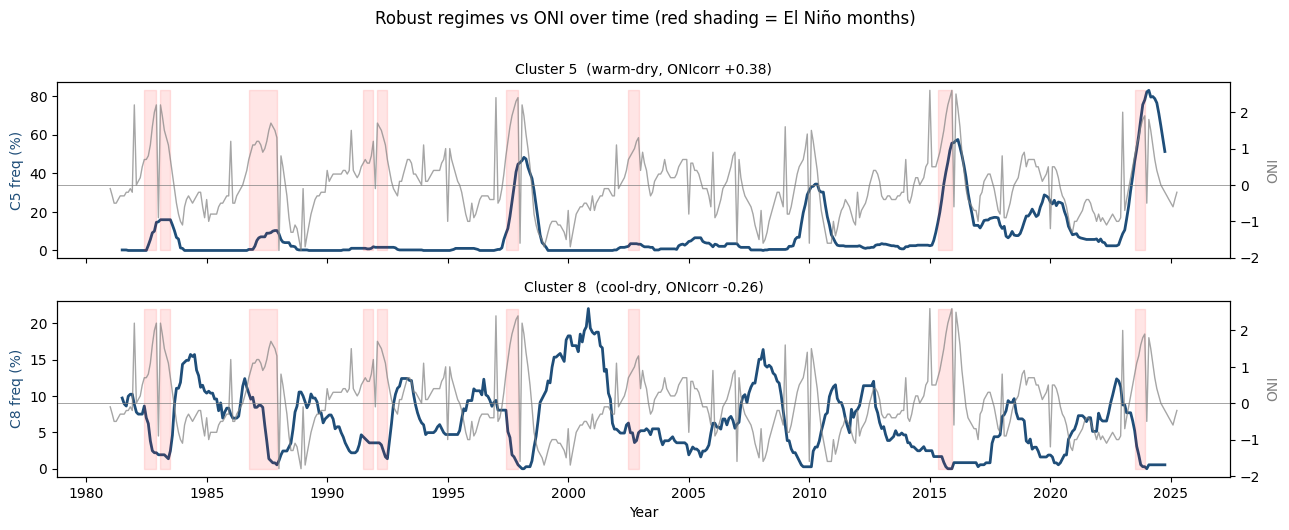

In [22]:
mon = monthly.copy(); mon['t'] = mon.index.to_timestamp()
fig, axes = plt.subplots(len(robust), 1, figsize=(13, 2.6*len(robust)), sharex=True, squeeze=False)
for i, k in enumerate(robust):
    ax = axes[i][0]
    freq = mon[f'f{k}'].rolling(12, center=True).mean() * 100
    ax.plot(mon['t'], freq, color='#1f4e79', lw=2, label=f'cluster {k} freq (12-mo)')
    ax.set_ylabel(f'C{k} freq (%)', color='#1f4e79')
    ax2 = ax.twinx()
    ax2.plot(mon['t'], mon['ONI'], color='grey', lw=1, alpha=.7)
    ax2.axhline(0, color='grey', lw=.5); ax2.set_ylabel('ONI', color='grey')
    ax2.fill_between(mon['t'], mon['ONI'].min(), mon['ONI'].max(),
                     where=(mon['Label'] == 'El Niño').values, color='red', alpha=.10)
    ax.set_title(f"Cluster {k}  ({tbl['type'][k]}, ONIcorr {resp['corr'][k]:+.2f})", fontsize=10)
axes[-1][0].set_xlabel('Year')
fig.suptitle('Robust regimes vs ONI over time (red shading = El Niño months)', y=1.01)
plt.tight_layout(); plt.show()

## 9. Regime frequency by ENSO phase

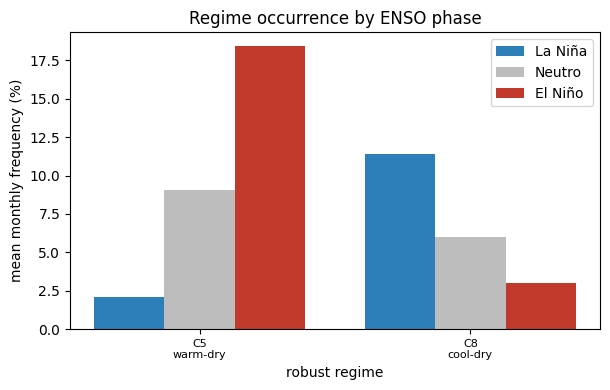

           f5    f8
Label              
La Niña   2.1  11.4
Neutro    9.0   6.0
El Niño  18.4   3.0


In [23]:
phase_order = ['La Niña', 'Neutro', 'El Niño']
phase_freq = (monthly.groupby('Label')[[f'f{k}' for k in range(N)]].mean() * 100).reindex(phase_order)
x = np.arange(len(robust)); w = 0.26
fig, ax = plt.subplots(figsize=(1.6*len(robust)+3, 4))
for j, ph in enumerate(phase_order):
    ax.bar(x + (j-1)*w, [phase_freq.loc[ph, f'f{k}'] for k in robust], w,
           label=ph, color=['#2c7fb8', '#bdbdbd', '#c0392b'][j])
ax.set_xticks(x); ax.set_xticklabels([f'C{k}\n{tbl["type"][k]}' for k in robust], fontsize=8)
ax.set_ylabel('mean monthly frequency (%)'); ax.set_xlabel('robust regime')
ax.set_title('Regime occurrence by ENSO phase'); ax.legend(); plt.tight_layout(); plt.show()
print(phase_freq[[f'f{k}' for k in robust]].round(1).to_string())

## 10. External validation — known Amazon drought and flood years — *new*

A test that only becomes possible with rainfall. Amazonia has a well-documented
record of severe droughts (1983, 1998, 2005, 2010, 2015–16, 2023–24 — the last
three being the widely reported "once-in-a-century" events) and pronounced wet
years (1989, 1999, 2009, 2012, 2021–22).

If the **dry regimes** are physically meaningful, their annual frequency should be
elevated in the drought years — and this is *independent of ONI*, so it is a genuine
out-of-model check rather than a restatement of §2. Significance comes from a
permutation test that shuffles the year labels (n = number of years), which is the
honest unit here.

> These year lists are taken from the literature, not derived from the data. They
> are a plausibility check, not a hypothesis test the model was tuned on.

driest regimes: [np.int64(12), np.int64(13), np.int64(11)] | wettest regimes: [np.int64(10), np.int64(2), np.int64(9)]


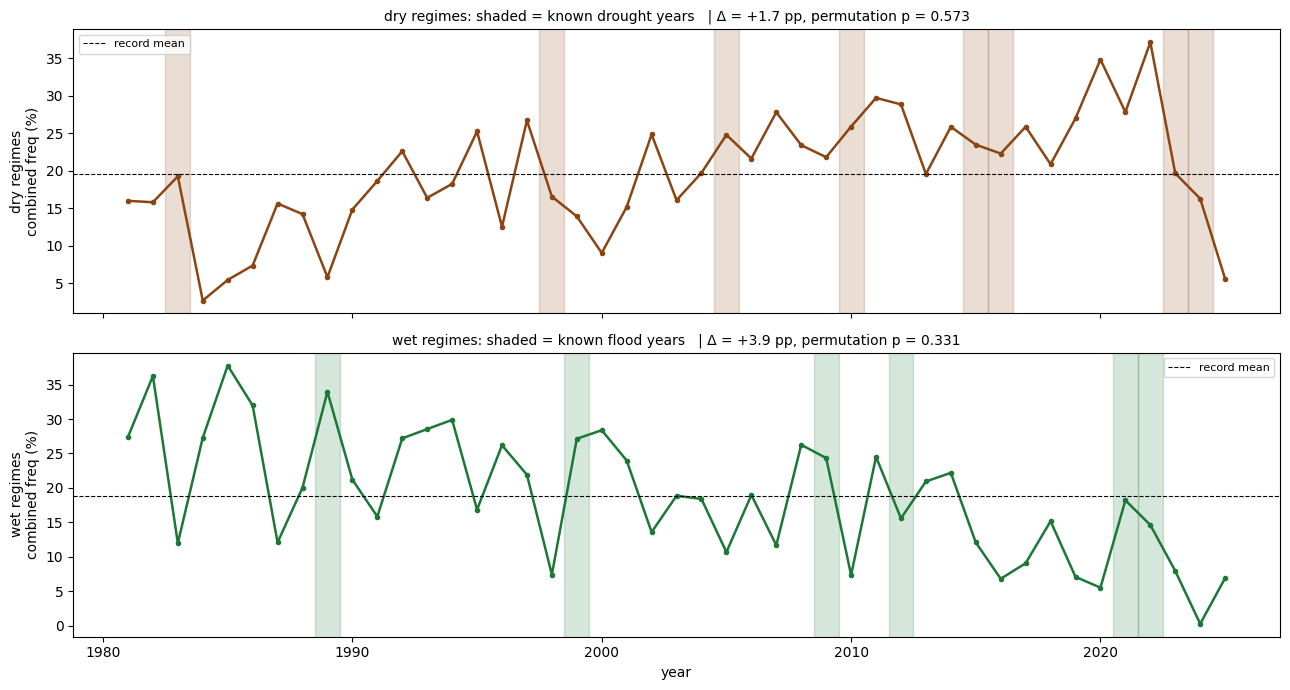

dry-regime frequency in drought years vs others: +1.7 pp (p=0.573)
wet-regime frequency in flood   years vs others: +3.9 pp (p=0.331)

8 driest years by regime occupancy (known drought years marked *):
  2022:  37.2%  
  2020:  34.9%  
  2011:  29.7%  
  2012:  28.9%  
  2021:  27.8%  
  2007:  27.8%  
  2019:  27.0%  
  1997:  26.7%  
  -> 0/8 of the model's driest years are documented drought years


In [24]:
DROUGHT_YEARS = [1983, 1998, 2005, 2010, 2015, 2016, 2023, 2024]
FLOOD_YEARS   = [1989, 1999, 2009, 2012, 2021, 2022]

if HAS_PREC:
    n_dry = max(3, N // 5)
    dry_regimes = order_P[:n_dry]           # driest regimes by precipitation anomaly
    wet_regimes = order_P[-n_dry:]
    print(f"driest regimes: {dry_regimes} | wettest regimes: {wet_regimes}")

    yearly = monthly.groupby('year')[[f'f{k}' for k in range(N)]].mean() * 100
    dry_freq = yearly[[f'f{k}' for k in dry_regimes]].sum(1)
    wet_freq = yearly[[f'f{k}' for k in wet_regimes]].sum(1)
    yrs_all  = dry_freq.index.values

    def perm_test(series, target_years, n_perm=20000, seed=0):
        # Difference in mean annual frequency, target years vs the rest,
        # against a null that shuffles which years carry the label.
        rng = np.random.default_rng(seed)
        vals = series.values
        m = np.isin(series.index.values, target_years)
        if m.sum() == 0: return np.nan, np.nan
        obs = vals[m].mean() - vals[~m].mean()
        null = np.empty(n_perm)
        for i in range(n_perm):
            p = rng.permutation(m)
            null[i] = vals[p].mean() - vals[~p].mean()
        return obs, float((np.abs(null) >= abs(obs)).mean())

    d_obs, d_p = perm_test(dry_freq, DROUGHT_YEARS)
    w_obs, w_p = perm_test(wet_freq, FLOOD_YEARS)

    fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
    for ax, series, tgt, name, col, obs, pv in [
            (axes[0], dry_freq, DROUGHT_YEARS, 'dry regimes',  '#8B4513', d_obs, d_p),
            (axes[1], wet_freq, FLOOD_YEARS,   'wet regimes',  '#1b7837', w_obs, w_p)]:
        ax.plot(series.index, series.values, color=col, lw=1.8, marker='o', ms=3)
        ax.axhline(series.mean(), color='k', lw=.8, ls='--', label='record mean')
        for y in tgt:
            if y in series.index:
                ax.axvspan(y-.5, y+.5, color=col, alpha=.18)
        ax.set_ylabel(f'{name}\ncombined freq (%)')
        ax.set_title(f'{name}: shaded = known '
                     f'{"drought" if "dry" in name else "flood"} years   '
                     f'| Δ = {obs:+.1f} pp, permutation p = {pv:.3f}'
                     f'{"  ** significant" if pv < 0.05 else ""}', fontsize=10)
        ax.legend(fontsize=8)
    axes[1].set_xlabel('year')
    plt.tight_layout(); plt.show()

    print(f"dry-regime frequency in drought years vs others: {d_obs:+.1f} pp (p={d_p:.3f})")
    print(f"wet-regime frequency in flood   years vs others: {w_obs:+.1f} pp (p={w_p:.3f})")
    top = dry_freq.sort_values(ascending=False).head(8)
    print("\n8 driest years by regime occupancy (known drought years marked *):")
    for y, v in top.items():
        print(f"  {int(y)}: {v:5.1f}%  {'*' if y in DROUGHT_YEARS else ''}")
    hits = sum(1 for y in top.index if y in DROUGHT_YEARS)
    print(f"  -> {hits}/8 of the model's driest years are documented drought years")

## 11. Did the extra channel actually buy anything? — *new*

The reason precipitation was added was to raise the ENSO detection ceiling, so the
honest test is a head-to-head against the temperature-only run on **identical
machinery**: same clusters count, same monthly series, same null, same corrections.

Two different things could improve, and they are worth keeping apart:
- **Statistical power** — more clusters surviving FWER, a stronger omnibus, larger
  |corr|. This is what "raise the ceiling" meant.
- **Physical specificity** — whether an ENSO-linked regime can now be corroborated
  in a second, independent field (§7). This can improve even if power does not.

INFO:root:loaded cached daily tensor from ../data/era5/.daily_cache/daily_e7711dba3b5c50b3.pt


INFO:root:applied per-month per-cell deseasonalised standardisation (anomalies)


                      clusters  omnibus  omnibus_p  n_FWER_sig  n_raw_sig  max_abs_corr
temperature only          15.0    0.485      0.013         3.0        8.0         0.381
temperature + precip      15.0    0.421      0.013         2.0        7.0         0.376


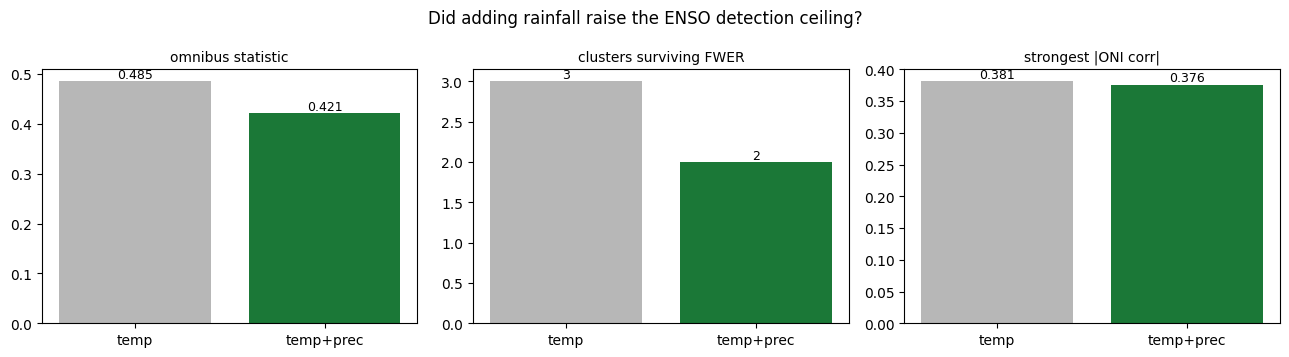


FWER-significant clusters: 3 -> 2 (-1)
VERDICT: rainfall did NOT raise the detection ceiling. Given the low precipitation η² in §I.8, the channel is under-used rather than uninformative — see the caveat in the summary. Its value here is physical corroboration (§7), not extra power.


In [25]:
import yaml
REF_CONFIG = 'checkpoint/temperature-era-amazonia-15-anom/params-temperature-era-amazonia-15-anom.yaml'
REF_SAVE   = 'results/temperature-era-amazonia-15-anom'

def enso_summary_from(cfg_path, save_path):
    # Rebuild the monthly ENSO statistics for another run from its cached F tensors.
    pr = yaml.safe_load(open(cfg_path))
    ds_ = Era5Dataset(transform=None, surf_vars=pr['data']['surf_vars'],
                      lat_lim=pr['data']['lat_limit'], lon_lim=pr['data']['lon_limit'],
                      split_val=True, val_years=tuple(pr['data']['val_years']),
                      deseason_standardize=pr['data'].get('deseason_standardize', False))
    Fa = torch.load(os.path.join(save_path, 'F.pt'), weights_only=False)
    Fb = torch.load(os.path.join(save_path, 'F_val.pt'), weights_only=False)
    n  = pr['criterion']['num_proto']
    c  = torch.cat([Fa.argmax(1).cpu(), Fb.argmax(1).cpu()]).numpy()
    d  = pd.to_datetime(list(ds_.time) + list(ds_.val_time))
    m  = es.build_monthly(pd.DataFrame({'cluster_id': c, 'date': d}), oni, n)
    st, pv = es.omnibus_test(m, n, n_perm=N_PERM)
    rr = es.oni_response(m, n, n_perm=N_PERM)
    return dict(clusters=n, omnibus=round(st, 3), omnibus_p=round(pv, 4),
                n_FWER_sig=int((rr.p_fwer < 0.05).sum()),
                n_raw_sig=int((rr.p_raw < 0.05).sum()),
                max_abs_corr=round(float(rr['corr'].abs().max()), 3))

rows = {}
try:
    rows['temperature only'] = enso_summary_from(REF_CONFIG, REF_SAVE)
except Exception as e:
    print('reference (temperature-only) run unavailable:', repr(e))
rows['temperature + precip'] = dict(clusters=N, omnibus=round(stat, 3), omnibus_p=round(p, 4),
                                    n_FWER_sig=int((resp.p_fwer < 0.05).sum()),
                                    n_raw_sig=int((resp.p_raw < 0.05).sum()),
                                    max_abs_corr=round(float(resp['corr'].abs().max()), 3))
cmp_tbl = pd.DataFrame(rows).T
print(cmp_tbl.to_string())

if len(rows) == 2:
    a, b = rows['temperature only'], rows['temperature + precip']
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
    for ax, key, ttl in [(axes[0], 'omnibus', 'omnibus statistic'),
                         (axes[1], 'n_FWER_sig', 'clusters surviving FWER'),
                         (axes[2], 'max_abs_corr', 'strongest |ONI corr|')]:
        ax.bar(['temp', 'temp+prec'], [a[key], b[key]], color=['#b7b7b7', '#1b7837'])
        ax.set_title(ttl, fontsize=10)
        for i, v in enumerate([a[key], b[key]]):
            ax.text(i, v, f'{v}', ha='center', va='bottom', fontsize=9)
    fig.suptitle('Did adding rainfall raise the ENSO detection ceiling?', fontsize=12)
    plt.tight_layout(); plt.show()

    gained = b['n_FWER_sig'] - a['n_FWER_sig']
    print(f"\nFWER-significant clusters: {a['n_FWER_sig']} -> {b['n_FWER_sig']} ({gained:+d})")
    print("VERDICT: " + (
        "rainfall raised the detection ceiling." if gained > 0 else
        "rainfall did NOT raise the detection ceiling. Given the low precipitation η² "
        "in §I.8, the channel is under-used rather than uninformative — see the caveat "
        "in the summary. Its value here is physical corroboration (§7), not extra power."))

## Summary — what can you conclude?

Read it in this order:

1. **Does the model use rainfall at all?** (§I.8) — if the precipitation η² is
   negligible, treat every rainfall statement below as decoration and retrain with a
   transformed precipitation channel first.
2. **Omnibus** (§II.1) significant? If not, stop — no ENSO story.
3. Trust a cluster only if it is **FWER-significant (red)** in §II.2, its **CI
   excludes 0** in §II.3, **and** it sits **near the diagonal** in §II.5.
4. The **continuous-ONI** test (§II.2) is the primary, most powerful result; the
   binary El Niño anomaly (§II.3) is the familiar view but weaker.
5. **The rainfall payoff** is §II.7 and §II.10: a regime that matches the El Niño
   fingerprint in *both* temperature and rainfall, and whose occupancy spikes in
   documented drought years, is a much stronger claim than anything the
   temperature-only model could support — because it is corroborated by an
   independent field and by external events.
6. **Did it help?** (§II.11) — the head-to-head against the temperature-only run is
   the bottom line. Note that with ~17 El Niño episodes the episode-level power
   ceiling is set by the *record*, not by the number of input variables: a second
   field makes each regime more physically specific, it does not manufacture new
   degrees of freedom. If few clusters survive FWER, that remains the honest ceiling
   of the data, not a modelling failure.

**Known caveat:** precipitation is standardised with the same per-month per-cell
z-score as temperature despite being strongly non-Gaussian (§I.8 quantifies the
skew). If the rainfall channel looks degenerate or dominated by extremes, the first
thing to try is a log or cube-root transform before standardising, then re-run this
notebook against the new checkpoint.